# Задание 4.2

5 мужчин и 5 женщин случайным образом рассаживаются в ряд на 10 мест. Найдите вероятности следующих событий: $A$ — любые две женщины не сидят рядом; $B$ — все мужчины сидят рядом.

**Ответ:** $\mathbb P(A)=\mathbb P(B)=\dfrac{1}{42}$.

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**Вероятностная модель.** Элементарный исход — перестановка 10 человек по 10 местам, $|\Omega|=10!$, все исходы равновозможны (классическая схема).

Удобнее заметить, что события $A$ и $B$ зависят только от того, **какие места заняли женщины**. Каждому набору из 5 «женских» мест соответствует одинаковое число $5!\cdot5!$ перестановок, поэтому все $C_{10}^5=252$ наборов равновероятны:

$$
\mathbb P(\cdot)=\frac{(\text{число подходящих наборов мест})\cdot5!\,5!}{10!}=\frac{\text{число подходящих наборов}}{C_{10}^5}.
$$

**Событие $A$** (никакие две женщины не рядом). Число способов выбрать $k$ попарно несоседних мест из $n$ в ряду равно $C_{n-k+1}^{k}$ (между выбранными местами должны стоять хотя бы по одному «пустому»: убираем по одному месту между соседними выбранными — получаем произвольный выбор $k$ из $n-k+1$). При $n=10$, $k=5$: $C_6^5=6$ (это места $1,3,5,7,9$; $\ 2,4,6,8,10$ и ещё 4 варианта с одним «двойным» промежутком). Значит

$$
\mathbb P(A)=\frac{6}{252}=\frac{1}{42}\approx0{,}0238095 .
$$

**Событие $B$** (все мужчины рядом). Мужчины занимают 5 подряд идущих мест — блок; начало блока может быть на местах $1,\dots,6$, т.е. 6 вариантов:

$$
\mathbb P(B)=\frac{6\cdot5!\cdot5!}{10!}=\frac{6}{252}=\frac{1}{42}.
$$

**Статистическая проверка:** моделируем $N$ случайных рассадок (случайных перестановок) и строим $\hat p=N(\cdot)/N$ в зависимости от $N$.

Перебор: всего наборов 252, благоприятных для A: 6, для B: 6
P(A) = 1/42 = 0.0238095,  P(B) = 1/42 = 0.0238095


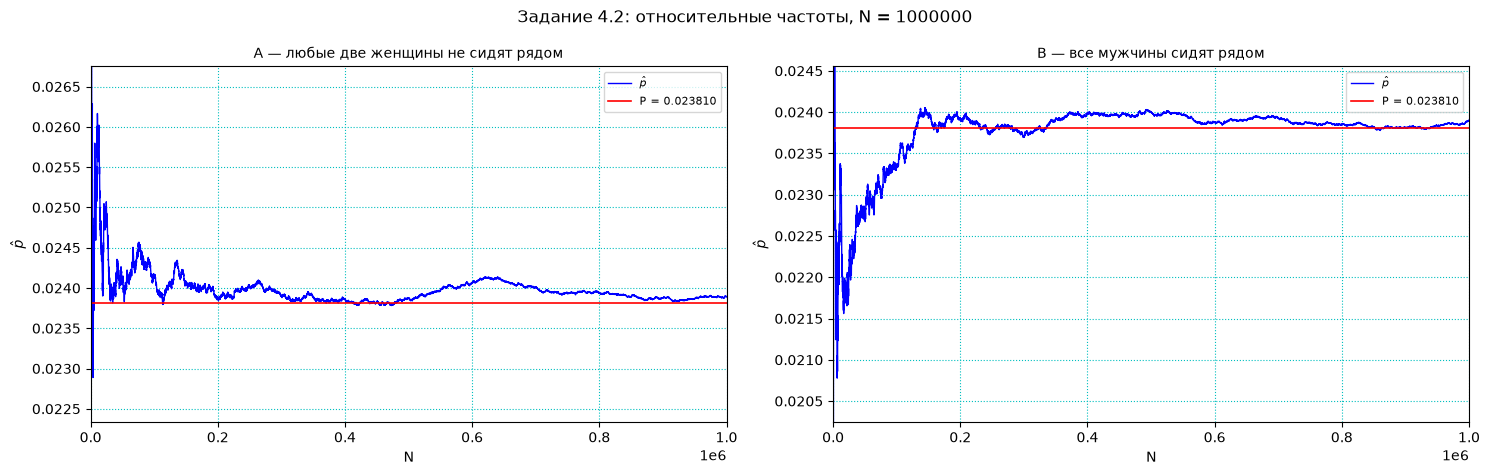

Моделирование: p̂(A) = 0.0238930,  p̂(B) = 0.0238970;  1/42 = 0.0238095


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from fractions import Fraction

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


# ---------- Точный подсчёт перебором всех C(10,5) наборов женских мест ----------
cnt_A = cnt_B = total = 0
for women in combinations(range(10), 5):
    men = sorted(set(range(10)) - set(women))
    total += 1
    cnt_A += all(b - a > 1 for a, b in zip(women, women[1:]))   # соседние женские места не подряд
    cnt_B += men[-1] - men[0] == 4                                # 5 мужчин занимают 5 подряд мест
PA, PB = Fraction(cnt_A, total), Fraction(cnt_B, total)
print(f"Перебор: всего наборов {total}, благоприятных для A: {cnt_A}, для B: {cnt_B}")
print(f"P(A) = {PA} = {float(PA):.7f},  P(B) = {PB} = {float(PB):.7f}")

# ---------- Моделирование: N случайных рассадок ----------
N = 1_000_000
row = np.array([1]*5 + [0]*5, dtype=np.int8)          # 1 — женщина, 0 — мужчина
seats = rng.permuted(np.tile(row, (N, 1)), axis=1)     # случайная перестановка в каждой строке

hits_A = ~np.any((seats[:, 1:] == 1) & (seats[:, :-1] == 1), axis=1)   # нет двух женщин рядом
men = seats == 0
first = men.argmax(axis=1)                                             # место первого мужчины
last = 9 - men[:, ::-1].argmax(axis=1)                                 # место последнего мужчины
hits_B = (last - first) == 4                                           # мужчины сидят блоком

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
pA = plot_freq(axes[0], hits_A, float(PA), "A — любые две женщины не сидят рядом")
pB = plot_freq(axes[1], hits_B, float(PB), "B — все мужчины сидят рядом")
fig.suptitle(f"Задание 4.2: относительные частоты, N = {N}")
fig.tight_layout()
plt.show()

print(f"Моделирование: p̂(A) = {pA:.7f},  p̂(B) = {pB:.7f};  1/42 = {1/42:.7f}")